# XGBoost + Extra Trees stacking experiment

Run this standalone notebook in Google Colab after both base-model training notebooks. It reads their saved validation and test predictions, fits one Ridge meta-model on validation predictions, and compares all three methods on the untouched test predictions.

**Important:** the validation base predictions came from train-only models, but the test base predictions came from train+validation models. This is an exploratory stack; its Ridge file alone is not a deployable forecast pipeline. For a final production stack, generate time-ordered out-of-fold base predictions and validate the entire refit process on a later holdout.

In [1]:
%pip install -q pandas scikit-learn==1.6.1 joblib matplotlib seaborn

## Mount Drive and locate base-model predictions

The XGBoost and ETR notebooks must already have saved their validation and test prediction CSVs in `MyDrive/demand-forecasting/artifacts/predictions`. No horizon training CSV or future-feature CSV is needed here.

In [2]:
import json
import platform
import shutil
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from google.colab import drive
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

drive.mount('/content/drive')
DRIVE_PROJECT_DIR = Path('/content/drive/MyDrive/demand-forecasting')
DRIVE_ARTIFACT_DIR = DRIVE_PROJECT_DIR / 'artifacts'
PREDICTION_DIR = DRIVE_ARTIFACT_DIR / 'predictions'
LOCAL_ARTIFACT_DIR = Path('/content/stacking_artifacts')
INPUT_FILES = {
    ('xgboost', 'validation'): PREDICTION_DIR / 'xgboost_validation_predictions.csv',
    ('etr', 'validation'): PREDICTION_DIR / 'etr_validation_predictions.csv',
    ('xgboost', 'test'): PREDICTION_DIR / 'xgboost_test_predictions.csv',
    ('etr', 'test'): PREDICTION_DIR / 'etr_test_predictions.csv',
}
missing_files = [str(path) for path in INPUT_FILES.values() if not path.exists()]
if missing_files:
    raise FileNotFoundError('Run both base-model notebooks first. Missing:\n' + '\n'.join(missing_files))
print('All four prediction files found:')
for path in INPUT_FILES.values():
    print(path)

Mounted at /content/drive
All four prediction files found:
/content/drive/MyDrive/demand-forecasting/artifacts/predictions/xgboost_validation_predictions.csv
/content/drive/MyDrive/demand-forecasting/artifacts/predictions/etr_validation_predictions.csv
/content/drive/MyDrive/demand-forecasting/artifacts/predictions/xgboost_test_predictions.csv
/content/drive/MyDrive/demand-forecasting/artifacts/predictions/etr_test_predictions.csv


## Align and validate identical forecast rows

A row is matched by forecast origin, target month, crop, location, and horizon. The notebook fails on duplicate keys, missing rows, different actual demand values, or overlapping validation/test target months.

In [3]:
KEY = ['forecast_origin_month', 'target_month', 'crop', 'location', 'forecast_horizon']
TARGET = 'future_demand_kg'
META_FEATURES = ['xgboost_prediction', 'etr_prediction']

def load_prediction(model, split):
    frame = pd.read_csv(INPUT_FILES[(model, split)], parse_dates=['forecast_origin_month', 'target_month'])
    prediction_column = 'xgboost_prediction' if model == 'xgboost' else 'etr_prediction'
    required = KEY + [TARGET, prediction_column, 'split']
    missing = [column for column in required if column not in frame.columns]
    if missing:
        raise ValueError(f'{model} {split} is missing columns: {missing}')
    if frame.empty or frame[required].isna().any().any():
        raise ValueError(f'{model} {split} contains no rows or missing required values.')
    if frame.duplicated(KEY).any():
        raise ValueError(f'{model} {split} contains duplicate forecast keys.')
    if not frame['split'].eq(split).all():
        raise ValueError(f'{model} {split} contains incorrect split labels.')
    if not np.isfinite(frame[[TARGET, prediction_column]].to_numpy(dtype=float)).all():
        raise ValueError(f'{model} {split} contains non-finite demand or predictions.')
    return frame[KEY + [TARGET, prediction_column]].copy()

def aligned_split(split):
    xgb = load_prediction('xgboost', split)
    etr = load_prediction('etr', split).rename(columns={TARGET: 'etr_actual'})
    joined = xgb.merge(etr, on=KEY, how='outer', validate='one_to_one', indicator=True)
    if len(joined) != len(xgb) or len(joined) != len(etr) or not joined['_merge'].eq('both').all():
        raise ValueError(f'{split} XGBoost and ETR prediction keys do not match exactly.')
    if not np.allclose(joined[TARGET], joined['etr_actual'], rtol=0, atol=1e-8):
        raise ValueError(f'{split} actual demand differs between model files.')
    return joined.drop(columns=['etr_actual', '_merge']).sort_values(KEY).reset_index(drop=True)

validation = aligned_split('validation')
test = aligned_split('test')
if validation['target_month'].max() >= test['target_month'].min():
    raise ValueError('Validation and test target months overlap or are out of order.')
if set(validation['forecast_horizon']) != set(range(1, 13)) or set(test['forecast_horizon']) != set(range(1, 13)):
    raise ValueError('Both splits must include every H1-H12 horizon.')
print(f"Validation: {len(validation):,} rows, {validation.target_month.min().date()} to {validation.target_month.max().date()}")
print(f"Test: {len(test):,} rows, {test.target_month.min().date()} to {test.target_month.max().date()}")

Validation: 1,620 rows, 2025-07-01 to 2025-09-01
Test: 1,620 rows, 2025-10-01 to 2025-12-01


## Fit the Ridge meta-model on validation predictions

Ridge sees only two inputs: the honest XGBoost and ETR validation predictions. `alpha=1.0` is fixed in advance; the test set is not used to choose it. Validation stack metrics below are in-sample diagnostics, not an unbiased score.

In [4]:
RIDGE_ALPHA = 1.0
stacker = Ridge(alpha=RIDGE_ALPHA)
stacker.fit(validation[META_FEATURES], validation[TARGET])
validation['stacking_prediction'] = np.maximum(stacker.predict(validation[META_FEATURES]), 0)
test['stacking_prediction'] = np.maximum(stacker.predict(test[META_FEATURES]), 0)
print(f'Intercept: {stacker.intercept_:.3f}')
print(dict(zip(META_FEATURES, stacker.coef_)))
print('A Ridge coefficient is not automatically a percentage weight; coefficients may be negative or sum to more than one.')

Intercept: -91.921
{'xgboost_prediction': np.float64(0.7604608872578766), 'etr_prediction': np.float64(0.338714607641416)}
A Ridge coefficient is not automatically a percentage weight; coefficients may be negative or sum to more than one.


## Compare validation diagnostics and untouched test metrics

Lower MAE, RMSE, and WAPE are better; higher R² is better. Select the final method using the untouched test comparison, while remembering the test period should not be used for repeated tuning.

In [5]:
MODEL_COLUMNS = {'xgboost': 'xgboost_prediction', 'extra_trees': 'etr_prediction', 'stacking': 'stacking_prediction'}

def score(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    denominator = np.abs(actual).sum()
    return {
        'mae': float(mean_absolute_error(actual, predicted)),
        'rmse': float(np.sqrt(mean_squared_error(actual, predicted))),
        'wape': float(np.abs(actual - predicted).sum() / denominator) if denominator > 0 else np.nan,
        'r2': float(r2_score(actual, predicted)),
    }

records = []
for split_name, frame in [('validation', validation), ('test', test)]:
    for model_name, column in MODEL_COLUMNS.items():
        records.append({'model': model_name, 'split': split_name, 'forecast_horizon': 'overall', 'rows': len(frame), **score(frame[TARGET], frame[column])})
        for horizon, group in frame.groupby('forecast_horizon'):
            records.append({'model': model_name, 'split': split_name, 'forecast_horizon': int(horizon), 'rows': len(group), **score(group[TARGET], group[column])})
metrics = pd.DataFrame(records)
print('Overall metrics (stacking validation score is in-sample):')
display(metrics[metrics['forecast_horizon'].eq('overall')].sort_values(['split', 'mae']))
print('Test metrics by horizon:')
display(metrics[(metrics['split'].eq('test')) & (metrics['forecast_horizon'].ne('overall'))])

Overall metrics (stacking validation score is in-sample):


,model,split,forecast_horizon,rows,mae,rmse,wape,r2
39,xgboost,test,overall,1620,544.264030,679.576577,0.209158,0.524070
65,stacking,test,overall,1620,551.188292,692.093422,0.211819,0.506377
52,extra_trees,test,overall,1620,578.047291,741.623414,0.222140,0.433196
26,stacking,validation,overall,1620,541.847217,694.947196,0.202812,0.573908
0,xgboost,validation,overall,1620,543.074354,723.622668,0.203271,0.538019
13,extra_trees,validation,overall,1620,558.355187,739.769330,0.208991,0.517172


Test metrics by horizon:


,model,split,forecast_horizon,rows,mae,rmse,wape,r2
40,xgboost,test,1,135,544.948162,687.532267,0.209421,0.512862
41,xgboost,test,2,135,544.953766,694.962006,0.209423,0.502276
42,xgboost,test,3,135,553.576672,683.239471,0.212737,0.518926
43,xgboost,test,4,135,548.677597,670.611924,0.210854,0.536544
44,xgboost,test,5,135,552.421036,682.436451,0.212292,0.520056
45,xgboost,test,6,135,555.617453,688.346370,0.213521,0.511707
46,xgboost,test,7,135,542.260092,678.799556,0.208388,0.525158
47,xgboost,test,8,135,547.084096,686.486282,0.210241,0.514343
48,xgboost,test,9,135,543.347741,674.895321,0.208806,0.530604
49,xgboost,test,10,135,533.249381,666.402666,0.204925,0.542343


## Visualize the test comparison

The same three graph types as the XGBoost notebook are displayed separately. Each graph compares XGBoost, Extra Trees, and the Ridge stack on the test set.

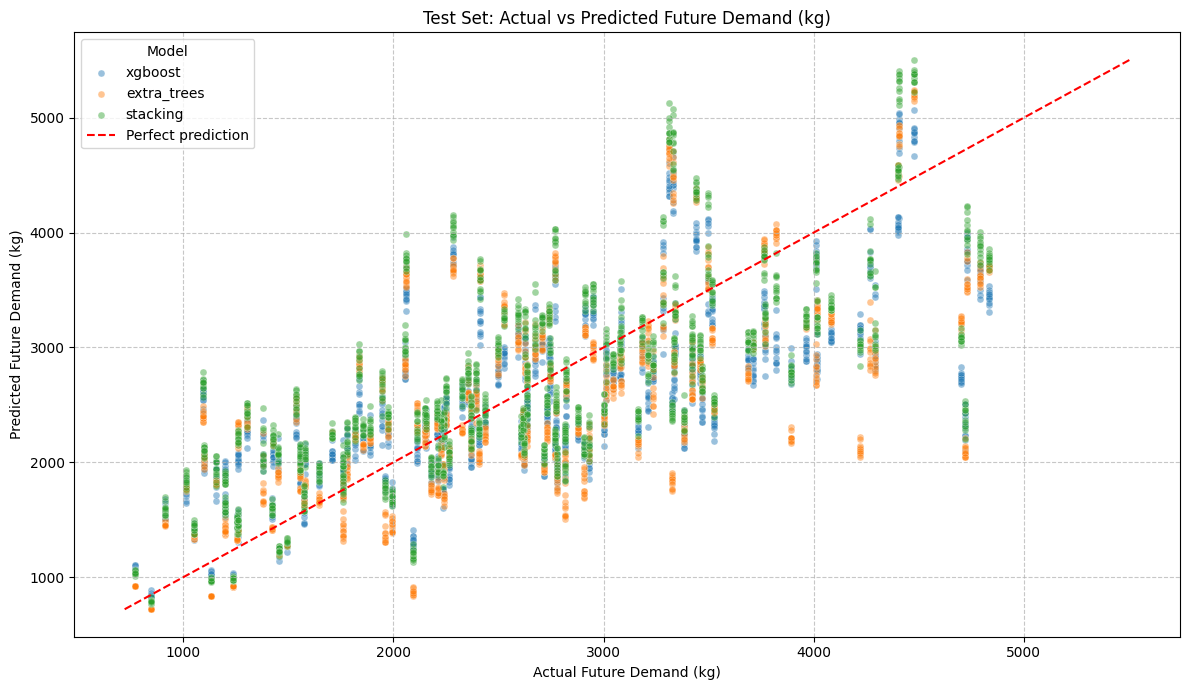

In [6]:
# Plot 1: actual versus predicted demand on the test set
actual = test[TARGET]
lower = min(actual.min(), *(test[column].min() for column in MODEL_COLUMNS.values()))
upper = max(actual.max(), *(test[column].max() for column in MODEL_COLUMNS.values()))
plt.figure(figsize=(12, 7))
for name, column in MODEL_COLUMNS.items():
    sns.scatterplot(x=actual, y=test[column], alpha=0.45, s=25, label=name)
plt.plot([lower, upper], [lower, upper], 'r--', label='Perfect prediction')
plt.title('Test Set: Actual vs Predicted Future Demand (kg)')
plt.xlabel('Actual Future Demand (kg)')
plt.ylabel('Predicted Future Demand (kg)')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(title='Model')
plt.tight_layout()
plt.show()

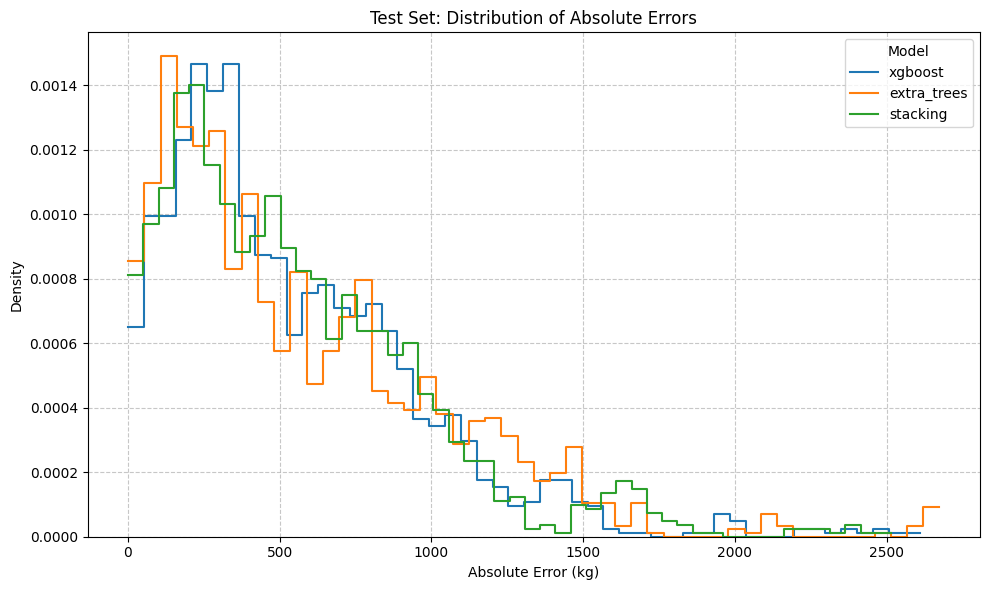

In [7]:
# Plot 2: distribution of absolute test errors
plt.figure(figsize=(10, 6))
for name, column in MODEL_COLUMNS.items():
    errors = (test[column] - actual).abs()
    sns.histplot(errors, bins=50, element='step', fill=False, stat='density', label=name)
plt.title('Test Set: Distribution of Absolute Errors')
plt.xlabel('Absolute Error (kg)')
plt.ylabel('Density')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(title='Model')
plt.tight_layout()
plt.show()

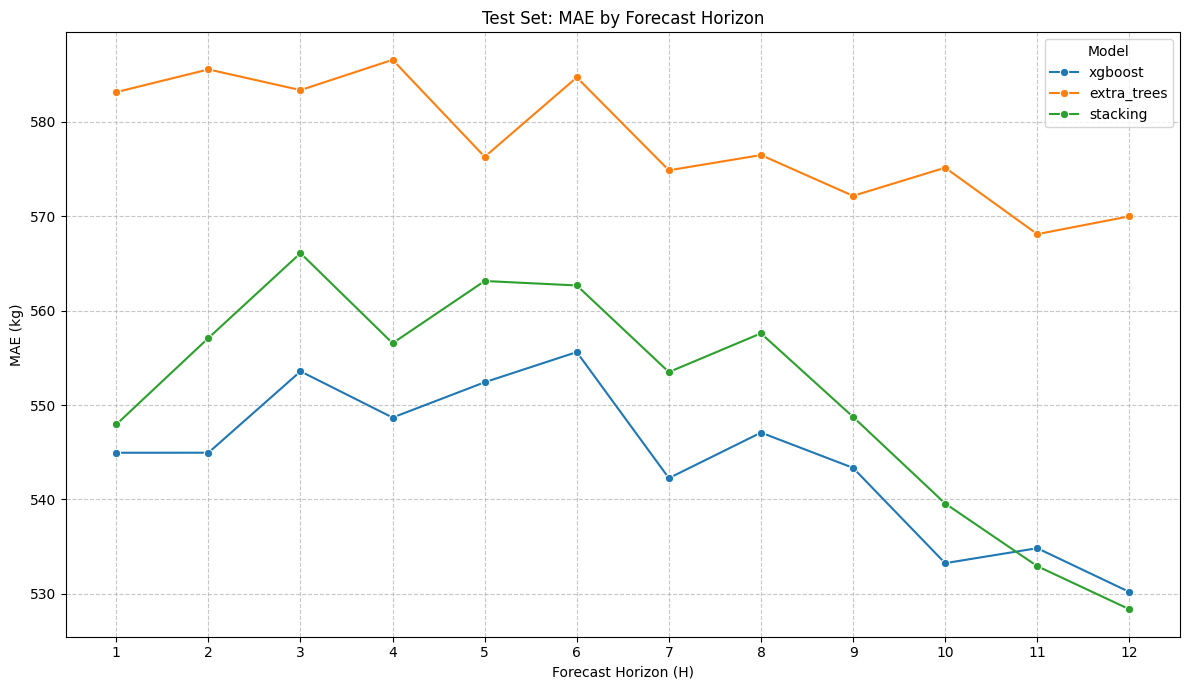

In [8]:
# Plot 3: MAE by forecast horizon on the test set
horizon_metrics = metrics[(metrics['split'].eq('test')) & (metrics['forecast_horizon'].ne('overall'))].copy()
horizon_metrics['forecast_horizon'] = horizon_metrics['forecast_horizon'].astype(int)
plt.figure(figsize=(12, 7))
sns.lineplot(data=horizon_metrics, x='forecast_horizon', y='mae', hue='model', marker='o')
plt.title('Test Set: MAE by Forecast Horizon')
plt.xlabel('Forecast Horizon (H)')
plt.ylabel('MAE (kg)')
plt.xticks(range(1, 13))
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(title='Model')
plt.tight_layout()
plt.show()

## Save experiment artifacts locally and to Google Drive

Save the fitted Ridge meta-model, aligned comparison predictions, metrics, and metadata. The Ridge file takes two base-model predictions as input; it cannot forecast directly from `future_horizon_features.csv`.

In [9]:
local_model_dir = LOCAL_ARTIFACT_DIR / 'models'
local_prediction_dir = LOCAL_ARTIFACT_DIR / 'predictions'
local_report_dir = LOCAL_ARTIFACT_DIR / 'reports'
for directory in [local_model_dir, local_prediction_dir, local_report_dir]:
    directory.mkdir(parents=True, exist_ok=True)

model_file = local_model_dir / 'experimental_ridge_stacker.joblib'
validation_file = local_prediction_dir / 'stacking_validation_comparison.csv'
test_file = local_prediction_dir / 'stacking_test_comparison.csv'
metrics_file = local_report_dir / 'stacking_metrics.csv'
metadata_file = local_report_dir / 'stacking_training_metadata.json'
joblib.dump(stacker, model_file)
validation.assign(absolute_error=(validation[TARGET] - validation['stacking_prediction']).abs()).to_csv(validation_file, index=False)
test.assign(absolute_error=(test[TARGET] - test['stacking_prediction']).abs()).to_csv(test_file, index=False)
metrics.to_csv(metrics_file, index=False)
metadata = {
    'model': 'experimental_ridge_stacker',
    'status': 'exploratory_not_deployable_without_base_models_and_time_ordered_oof_validation',
    'target': TARGET, 'meta_features': META_FEATURES, 'ridge_alpha': RIDGE_ALPHA,
    'fit_data': 'base-model validation predictions',
    'evaluation_data': 'base-model test predictions',
    'validation_metrics_are_in_sample': True,
    'base_model_fit_mismatch': 'validation base models train-only; test base models train+validation',
    'ridge_intercept': float(stacker.intercept_),
    'ridge_coefficients': dict(zip(META_FEATURES, map(float, stacker.coef_))),
    'versions': {'python': platform.python_version(), 'pandas': pd.__version__, 'scikit_learn': sklearn.__version__, 'joblib': joblib.__version__},
}
metadata_file.write_text(json.dumps(metadata, indent=2), encoding='utf-8')

local_files = [model_file, validation_file, test_file, metrics_file, metadata_file]
for source in local_files:
    destination = DRIVE_ARTIFACT_DIR / source.parent.name / source.name
    destination.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(source, destination)
    print(f'Saved: {destination}')

Saved: /content/drive/MyDrive/demand-forecasting/artifacts/models/experimental_ridge_stacker.joblib
Saved: /content/drive/MyDrive/demand-forecasting/artifacts/predictions/stacking_validation_comparison.csv
Saved: /content/drive/MyDrive/demand-forecasting/artifacts/predictions/stacking_test_comparison.csv
Saved: /content/drive/MyDrive/demand-forecasting/artifacts/reports/stacking_metrics.csv
Saved: /content/drive/MyDrive/demand-forecasting/artifacts/reports/stacking_training_metadata.json
